# EDA : Data visualisation and analysis 


**Import libraries**


In [1]:
import numpy as np 
import pandas as pd
import random 
import os  
import torch 
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredText


In [2]:
plt.style.use('ggplot')

def seed_set(seed=50):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
seed_set()

In [3]:
from xyz2graph import MolGraph, to_networkx_graph, to_plotly_figure
from plotly.offline import init_notebook_mode, iplot
import networkx as nx


In [4]:
# Folder of the dataset (NOT the csv file)
DATA_DIR = r'C:\Users\pc\Downloads\champs-scalar-coupling'
CSV_PATH = os.path.join(DATA_DIR, 'structures.csv')
XYZ_DIR  = os.path.join(DATA_DIR, 'structures')  
COUPLING_DIR  = os.path.join(DATA_DIR , 'scalar_coupling_contributions') 

In [5]:
init_notebook_mode(connected=True)
structures = pd.read_csv(CSV_PATH)
mol_names = structures.molecule_name.unique()

In [6]:
print(structures.head())


      molecule_name  atom_index atom         x         y         z
0  dsgdb9nsd_000001           0    C -0.012698  1.085804  0.008001
1  dsgdb9nsd_000001           1    H  0.002150 -0.006031  0.001976
2  dsgdb9nsd_000001           2    H  1.011731  1.463751  0.000277
3  dsgdb9nsd_000001           3    H -0.540815  1.447527 -0.876644
4  dsgdb9nsd_000001           4    H -0.523814  1.437933  0.906397


In [7]:
structures.head(3).to_dict(orient='records')

[{'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 0,
  'atom': 'C',
  'x': -0.0126981359,
  'y': 1.0858041578,
  'z': 0.0080009957999999},
 {'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 1,
  'atom': 'H',
  'x': 0.002150416,
  'y': -0.0060313176,
  'z': 0.0019761204},
 {'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 2,
  'atom': 'H',
  'x': 1.0117308433,
  'y': 1.4637511618,
  'z': 0.0002765748}]

In [8]:
molecule_atoms = [
    {
        'molecule_name': 'dsgdb9nsd_000001',
        'atom_index': 0,
        'atom': 'C',
        'x': -0.0126981359,
        'y': 1.0858041578,
        'z': 0.0080009957999999,
    },
    {
        'molecule_name': 'dsgdb9nsd_000001',
        'atom_index': 1,
        'atom': 'H',
        'x': 0.002150416,
        'y': -0.0060313176,
        'z': 0.0019761204,
    },
    {
        'molecule_name': 'dsgdb9nsd_000001',
        'atom_index': 2,
        'atom': 'H',
        'x': 1.0117308433,
        'y': 1.4637511618,
        'z': 0.0002765748,
    },
]

molecule_atoms

[{'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 0,
  'atom': 'C',
  'x': -0.0126981359,
  'y': 1.0858041578,
  'z': 0.0080009957999999},
 {'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 1,
  'atom': 'H',
  'x': 0.002150416,
  'y': -0.0060313176,
  'z': 0.0019761204},
 {'molecule_name': 'dsgdb9nsd_000001',
  'atom_index': 2,
  'atom': 'H',
  'x': 1.0117308433,
  'y': 1.4637511618,
  'z': 0.0002765748}]

In [9]:
mol_names = structures.molecule_name.unique()

In [10]:
def draw_random_mol():
    mol_name = random.choice(mol_names)
    mg = MolGraph()
    mg.read_xyz(os.path.join(XYZ_DIR, f'{mol_name}.xyz'))
    fig = to_plotly_figure(mg)
    iplot(fig)

def draw_random_networx_graph():
    mol_name = random.choice(mol_names)
    mg = MolGraph()
    mg.read_xyz(os.path.join(XYZ_DIR, f'{mol_name}.xyz'))
    G = to_networkx_graph(mg)
    print('Nodes:')
    print(list(G.nodes(data=True))[:5])
    print('Edges:')
    print(list(G.edges(data=True))[:5])
    nx.draw(G, with_labels=True)

In [11]:
draw_random_mol()

C:\Users\pc\AppData\Local\Temp\ipykernel_3788\2953702703.py:5: DeprecationWarning: to_plotly_figure is deprecated and will be removed in version 4.0.0. Use MolGraph.to_plotly() instead.
  fig = to_plotly_figure(mg)


In [12]:
draw_random_mol()

C:\Users\pc\AppData\Local\Temp\ipykernel_3788\2953702703.py:5: DeprecationWarning: to_plotly_figure is deprecated and will be removed in version 4.0.0. Use MolGraph.to_plotly() instead.
  fig = to_plotly_figure(mg)


C:\Users\pc\AppData\Local\Temp\ipykernel_3788\2953702703.py:12: DeprecationWarning: to_networkx_graph is deprecated and will be removed in version 4.0.0. Use MolGraph.to_networkx() instead.
  G = to_networkx_graph(mg)


Nodes:
[(0, {'element': 'N', 'xyz': (0.2654798939, -1.2136135244, 0.564796426)}), (1, {'element': 'C', 'xyz': (0.1420400301, -0.0935578448, 0.3085994399)}), (2, {'element': 'C', 'xyz': (-0.0237309669, 1.3329118592, 0.0142835989)}), (3, {'element': 'C', 'xyz': (-0.8366184774, 1.9869439674, 1.1653474151)}), (4, {'element': 'O', 'xyz': (-1.3013292817, 3.2708547961, 0.839168058)})]
Edges:
[(0, 1, {'length': np.float64(1.15559)}), (1, 2, {'length': np.float64(1.46592)}), (2, 3, {'length': np.float64(1.55354)}), (2, 8, {'length': np.float64(1.52174)}), (2, 9, {'length': np.float64(1.10019)})]


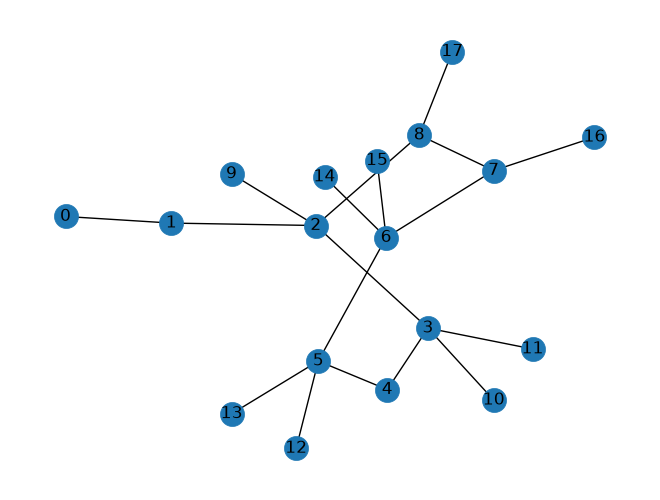

In [13]:
draw_random_networx_graph()

In [14]:
from matplotlib.animation import ArtistAnimation
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import Image, display 
import seaborn as sns 



In [15]:
TRAIN_FILE = r'C:\Users\pc\Downloads\champs-scalar-coupling\train.csv'
train_df = pd.read_csv(TRAIN_FILE)
train_df.head()


,id,molecule_name,atom_index_0,atom_index_1,type,scalar_coupling_constant
0,0,dsgdb9nsd_000001,1,0,1JHC,84.8076
1,1,dsgdb9nsd_000001,1,2,2JHH,-11.2570
2,2,dsgdb9nsd_000001,1,3,2JHH,-11.2548
3,3,dsgdb9nsd_000001,1,4,2JHH,-11.2543
4,4,dsgdb9nsd_000001,2,0,1JHC,84.8074


**To compare molecules fairly, we normalize each 1JHN pair: the H atom is translated to (0,0,0) and the molecule is rotated so that N lies at (1,0,0). This removes the effect of position and orientation in space, which do not influence the coupling constant, leaving only the internal geometry (distances and angles) that actually matters. It also lets us overlay molecules in the same frame and see how N's other neighbors are arranged."**

In [16]:
print(train_df.shape)                 # l-original: (4659076, 6)
print(train_df['type'].unique())      # l-original: 8 types

(4659076, 6)
['1JHC' '2JHH' '1JHN' '2JHN' '2JHC' '3JHH' '3JHC' '3JHN']


In [17]:

TEST_PATH = os.path.join(DATA_DIR, 'test.csv')
test_df = pd.read_csv(TEST_PATH)

In [18]:
print(test_df.shape)
print(test_df['type'].unique())


(2505190, 5)
['2JHC' '1JHC' '3JHH' '2JHH' '3JHC' '3JHN' '1JHN' '2JHN']


        train    test  train_%  test_%
type                                  
3JHC  1511207  811351    32.44   32.39
2JHC  1140867  613087    24.49   24.47
1JHC   709133  380968    15.22   15.21
3JHH   590529  317582    12.67   12.68
2JHH   377988  203201     8.11    8.11
3JHN   166613   90459     3.58    3.61
2JHN   119059   64647     2.56    2.58
1JHN    43680   23895     0.94    0.95


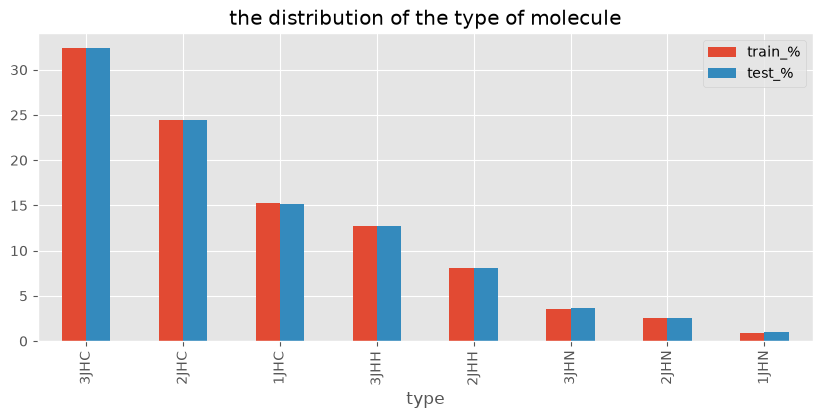

In [19]:
counts = pd.DataFrame({
    'train': train_df['type'].value_counts(),
    'test': test_df['type'].value_counts()
})
counts['train_%'] = (counts['train'] / counts['train'].sum() * 100).round(2)
counts['test_%'] = (counts['test'] / counts['test'].sum() * 100).round(2)
print(counts)
counts[['train_%', 'test_%']].plot(kind='bar', figsize=(10, 4))
plt.title('the distribution of the type of molecule')
plt.show()

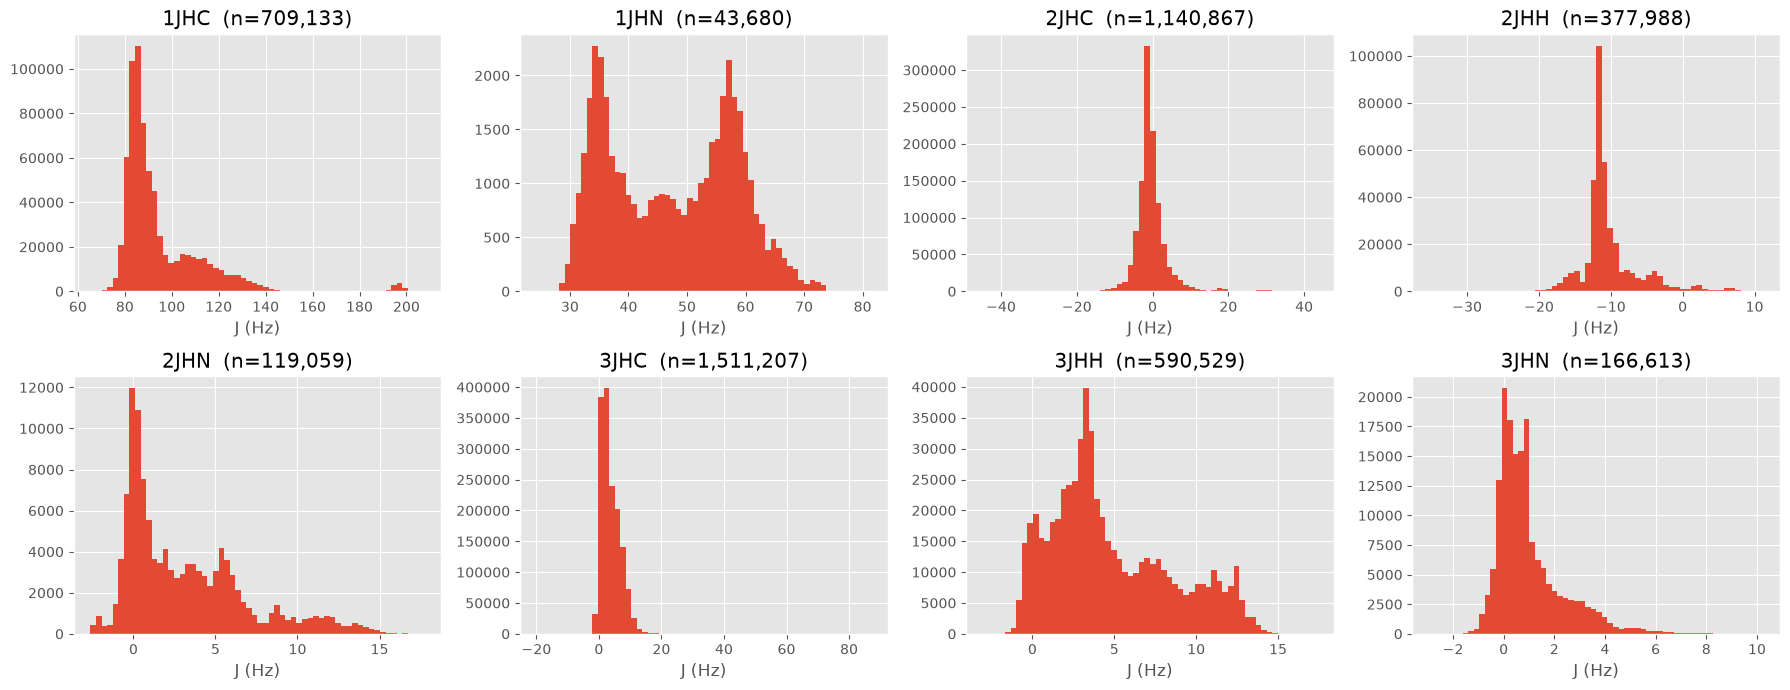

        count   mean    std    min     max
type                                      
1JHC   709133  94.97  18.29  65.35  207.71
1JHN    43680  47.49  10.90  24.32   81.40
2JHC  1140867  -0.27   4.52 -44.76   43.41
2JHH   377988 -10.28   3.98 -35.27   11.22
2JHN   119059   3.13   3.68  -2.62   17.74
3JHC  1511207   3.69   3.08 -19.89   86.96
3JHH   590529   4.77   3.71  -3.02   17.38
3JHN   166613   0.99   1.32  -2.94   10.25


In [20]:
types = sorted(train_df['type'].unique())
fig, axes = plt.subplots(2, 4, figsize=(18, 7))

for ax, t in zip(axes.ravel(), types):
    d = train_df.loc[train_df['type'] == t, 'scalar_coupling_constant']
    ax.hist(d, bins=60)
    ax.set_title(f'{t}  (n={len(d):,})')
    ax.set_xlabel('J (Hz)')

plt.tight_layout()
plt.show()

# jadwal rqmi: mean, std, min, max
print(train_df.groupby('type')['scalar_coupling_constant']
      .agg(['count', 'mean', 'std', 'min', 'max']).round(2))

In [21]:


def add_coords(df, idx):
    s = structures.rename(columns={
        'atom_index': f'atom_index_{idx}',
        'atom': f'atom_{idx}',
        'x': f'x_{idx}', 'y': f'y_{idx}', 'z': f'z_{idx}'})
    return df.merge(s, on=['molecule_name', f'atom_index_{idx}'], how='left')
    
train_df = add_coords(train_df, 0)
train_df  = add_coords(train_df, 1)
test_df = add_coords(test_df, 0)
test_df = add_coords(test_df, 1)

for df in (train_df, test_df):
    df['dist'] = np.sqrt((df['x_0'] - df['x_1'])**2 +
                         (df['y_0'] - df['y_1'])**2 +
                         (df['z_0'] - df['z_1'])**2).astype('float32')



In [22]:
train_df.head()

,id,molecule_name,atom_index_0,atom_index_1,type,scalar_coupling_constant,atom_0,x_0,y_0,z_0,atom_1,x_1,y_1,z_1,dist
0,0,dsgdb9nsd_000001,1,0,1JHC,84.8076,H,0.002150,-0.006031,0.001976,C,-0.012698,1.085804,0.008001,1.091953
1,1,dsgdb9nsd_000001,1,2,2JHH,-11.2570,H,0.002150,-0.006031,0.001976,H,1.011731,1.463751,0.000277,1.783120
2,2,dsgdb9nsd_000001,1,3,2JHH,-11.2548,H,0.002150,-0.006031,0.001976,H,-0.540815,1.447527,-0.876644,1.783147
3,3,dsgdb9nsd_000001,1,4,2JHH,-11.2543,H,0.002150,-0.006031,0.001976,H,-0.523814,1.437933,0.906397,1.783157
4,4,dsgdb9nsd_000001,2,0,1JHC,84.8074,H,1.011731,1.463751,0.000277,C,-0.012698,1.085804,0.008001,1.091952


In [23]:
train_df['dist'].isna().sum().astype('float32')

np.float32(0.0)

1JHC -0.705
1JHN -0.868
2JHC 0.287
2JHH 0.529
2JHN -0.161
3JHC 0.32
3JHH 0.264
3JHN 0.272


C:\Users\pc\AppData\Local\Temp\ipykernel_3788\916620396.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g['dist'].corr(g['scalar_coupling_constant']))


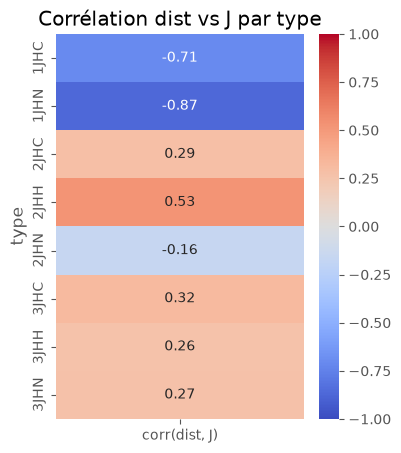

In [24]:
for t, g in train_df.groupby('type'):
    print(t, round(g['dist'].corr(g['scalar_coupling_constant']), 3))

corr_by_type = (train_df.groupby('type')
                .apply(lambda g: g['dist'].corr(g['scalar_coupling_constant']))
                .rename('corr(dist, J)')
                .to_frame())
plt.figure(figsize = (4 , 5))
sns.heatmap(corr_by_type  , annot =True , fmt = '.2f' , cmap ='coolwarm' ,vmin = -1 ,vmax =  1 ) 
plt.title('Corrélation dist vs J par type')
plt.show()



**the correlation between distance and j is so hight just for the type 1jhn or specifecly to the type 1j , for the others there is no strong relation between that feature and the others types (2j , 3j)**

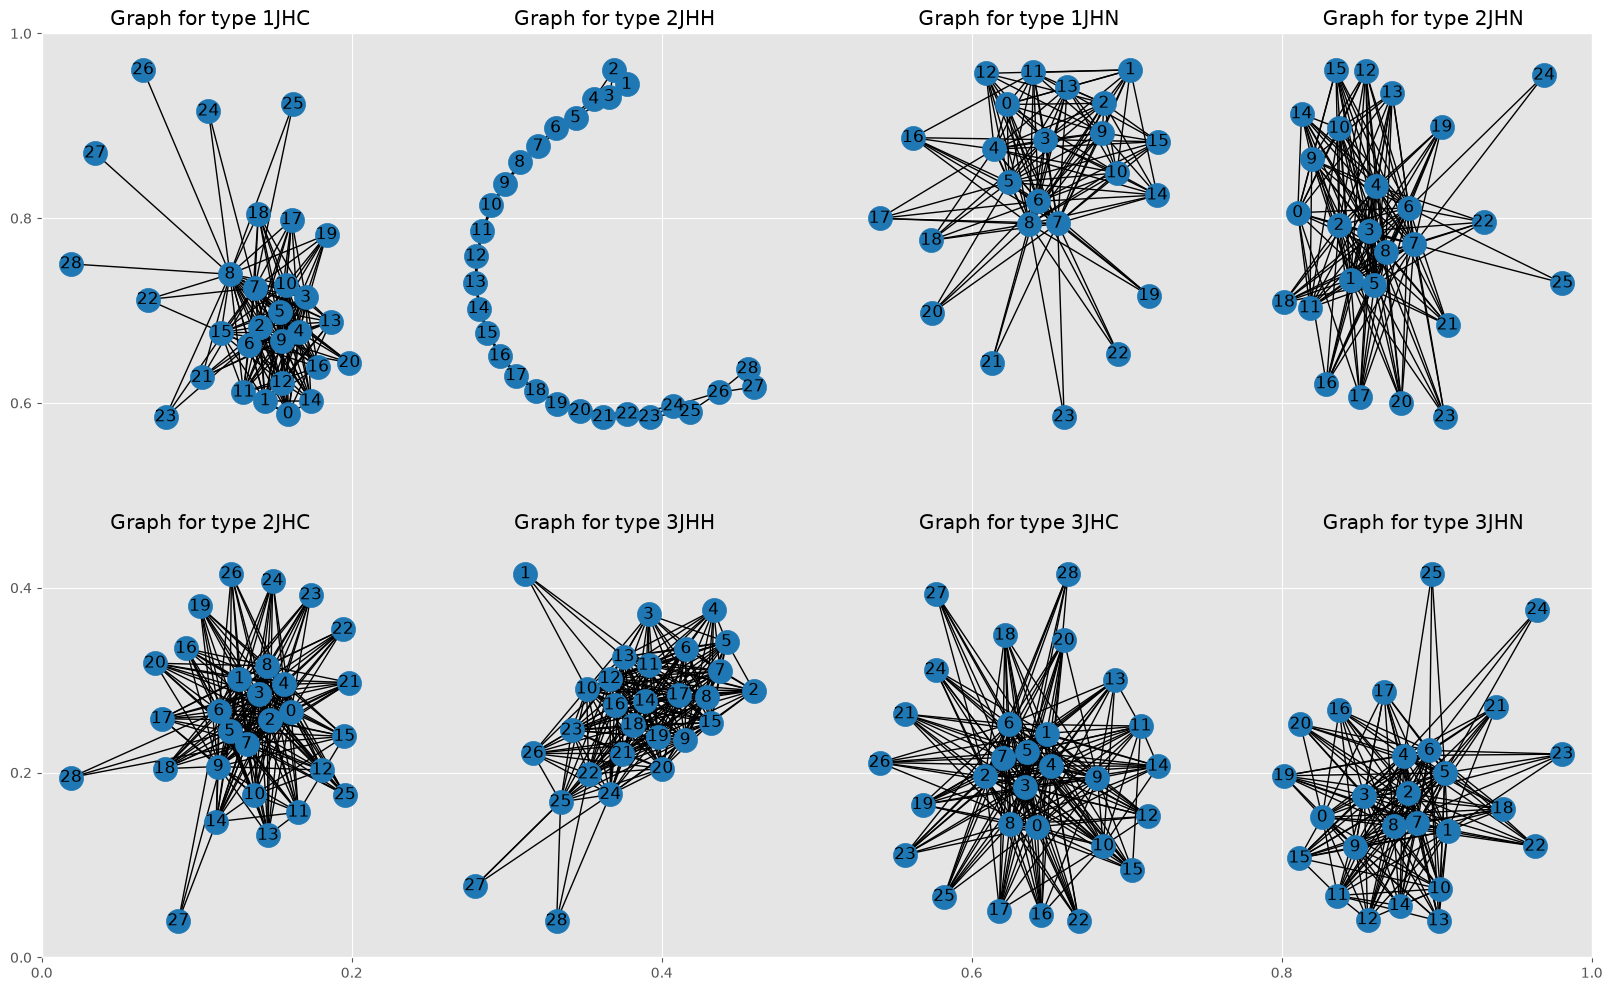

In [25]:
fig, ax = plt.subplots(figsize = (20, 12))
for i, t in enumerate(train_df['type'].unique()):
    train_type = train_df.loc[train_df['type'] == t]
    G = nx.from_pandas_edgelist(train_type, 'atom_index_0', 'atom_index_1', ['scalar_coupling_constant'])
    plt.subplot(2, 4, i + 1);
    nx.draw(G, with_labels=True);
    plt.title(f'Graph for type {t}')

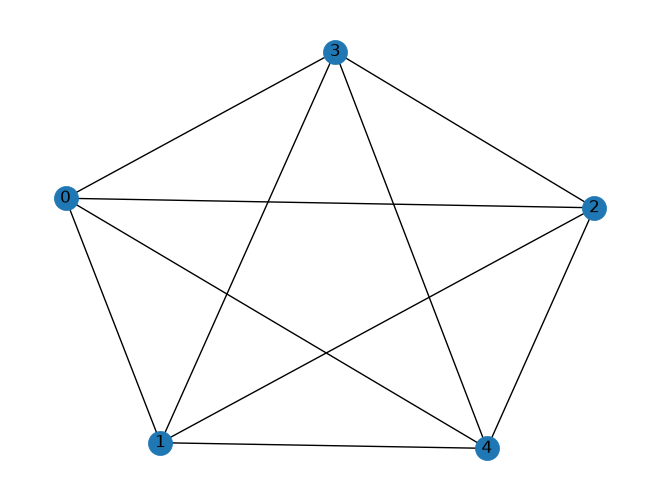

In [26]:
mol = train_df[train_df['molecule_name'] == 'dsgdb9nsd_000001']
G = nx.from_pandas_edgelist(mol, 'atom_index_0', 'atom_index_1', ['scalar_coupling_constant'])
nx.draw(G, with_labels=True)

In [27]:
COUPLING_DIR = os.path.join(DATA_DIR , 'scalar_coupling_contributions.csv')

In [28]:
scalar_coupling_constants = pd.read_csv(COUPLING_DIR)


In [29]:
DISPLAY_BONDS = False 



=== 1JHN : 10 samples (mrtbin b J) ===
            molecule_name  atom_index_0  atom_index_1   dist  scalar_coupling_constant
2293500  dsgdb9nsd_070698            12             2  1.018                    33.347
3737981  dsgdb9nsd_106803            19             8  1.019                    34.102
420138   dsgdb9nsd_014004             9             3  1.018                    35.979
115557   dsgdb9nsd_004503            11             4  1.017                    43.024
120724   dsgdb9nsd_004786            11             1  1.012                    46.226
1757406  dsgdb9nsd_057219            13             3  1.009                    51.599
4576001  dsgdb9nsd_128242            12             1  1.012                    54.667
1689208  dsgdb9nsd_054924            10             0  1.004                    57.158
3330192  dsgdb9nsd_095992             9             0  1.006                    58.359
4591680  dsgdb9nsd_129183             1             0  1.007                    63.048


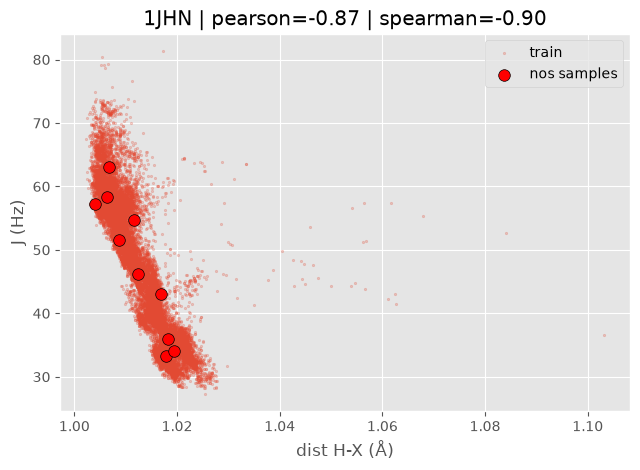

In [30]:

SELECTED_TYPES = ['1JHN']        
DIVS  = 10
SAMPLES        = 1             
DISPLAY_BONDS  = True            #
N_FRAMES       = 16              


samples_idx = {}
for t in SELECTED_TYPES:
    sub = train_df[train_df['type'] == t].copy()
    sub['bin'] = pd.qcut(sub['scalar_coupling_constant'], q=DIVS, duplicates='drop')
    samples_idx[t] = (sub.groupby('bin', observed=True)
                         .sample(SAMPLES, random_state=50)
                         .index.tolist())          # mrtbin men J sghira l kbira

for t, idx in samples_idx.items():
    print(f'\n=== {t} : {len(idx)} samples (mrtbin b J) ===')
    cols = ['molecule_name', 'atom_index_0', 'atom_index_1', 'dist', 'scalar_coupling_constant']
    print(train_df.loc[idx, cols].round(3).to_string())


fig, axes = plt.subplots(1, len(SELECTED_TYPES),
                         figsize=(6.5 * len(SELECTED_TYPES), 4.8), squeeze=False)
for ax, t in zip(axes[0], SELECTED_TYPES):
    d  = train_df[train_df['type'] == t]
    bg = d.sample(min(20000, len(d)), random_state=50)      # fond (bach ma yt9lch)
    ax.scatter(bg['dist'], bg['scalar_coupling_constant'], s=3, alpha=0.25, label='train')
    s = train_df.loc[samples_idx[t]]
    ax.scatter(s['dist'], s['scalar_coupling_constant'], s=70, color='red',
               edgecolor='black', zorder=3, label='nos samples')
    pear  = d['dist'].corr(d['scalar_coupling_constant'])
    spear = d['dist'].corr(d['scalar_coupling_constant'], method='spearman')
    ax.set_title(f'{t} | pearson={pear:.2f} | spearman={spear:.2f}')
    ax.set_xlabel('dist H-X (Å)')
    ax.set_ylabel('J (Hz)')
    ax.legend()
plt.tight_layout()
plt.show()



**Binning:** we split J (scalar_coupling_constant) into 10 quantile bins (`pd.qcut`), each bin
containing the same number of couplings, and draw one sample per bin. This gives us molecules
spread across the whole J range, to visualise how dist relates to J (feature engineering).


=== 1JHC : 10 samples ===
            molecule_name  atom_index_0  atom_index_1   dist  scalar_coupling_constant
234108   dsgdb9nsd_008373            10             0  1.096                    79.390
3988012  dsgdb9nsd_112722            20             7  1.095                    82.217
3905529  dsgdb9nsd_110730            16             6  1.100                    83.298
2915967  dsgdb9nsd_086190            24             8  1.098                    85.822
3526930  dsgdb9nsd_101516            11             0  1.093                    87.968
4022346  dsgdb9nsd_113500            17             6  1.096                    89.543
2555489  dsgdb9nsd_077299            13             3  1.091                    91.447
1431683  dsgdb9nsd_046439            10             3  1.095                    95.864
2564148  dsgdb9nsd_077530            17             7  1.094                   106.859
4565820  dsgdb9nsd_127690            13             6  1.083                   129.664


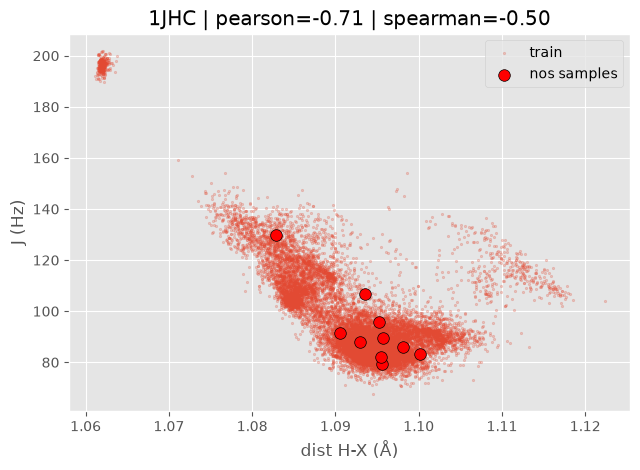

In [31]:
SELECTED_TYPES = ['1JHC']
DIVS           = 10
SAMPLES        = 1
DISPLAY_BONDS  = True
N_FRAMES       = 16

samples_idx = {}
for t in SELECTED_TYPES:
    sub = train_df[train_df['type'] == t].copy()
    sub['bin'] = pd.qcut(sub['scalar_coupling_constant'], q=DIVS, duplicates='drop')
    samples_idx[t] = (sub.groupby('bin', observed=True)
                         .sample(SAMPLES, random_state=50)
                         .index.tolist())

for t, idx in samples_idx.items():                      # <-- samples_idx
    print(f'\n=== {t} : {len(idx)} samples ===')
    cols = ['molecule_name', 'atom_index_0', 'atom_index_1', 'dist', 'scalar_coupling_constant']
    print(train_df.loc[idx, cols].round(3).to_string())

fig, axes = plt.subplots(1, len(SELECTED_TYPES),        # <-- subplots
                         figsize=(6.5 * len(SELECTED_TYPES), 4.8), squeeze=False)
for ax, t in zip(axes[0], SELECTED_TYPES):
    d  = train_df[train_df['type'] == t]
    bg = d.sample(min(20000, len(d)), random_state=50)
    ax.scatter(bg['dist'], bg['scalar_coupling_constant'], s=3, alpha=0.25, label='train')
    s = train_df.loc[samples_idx[t]]
    ax.scatter(s['dist'], s['scalar_coupling_constant'], s=70, color='red',
               edgecolor='black', zorder=3, label='nos samples')
    pear  = d['dist'].corr(d['scalar_coupling_constant'])
    spear = d['dist'].corr(d['scalar_coupling_constant'], method='spearman')
    ax.set_title(f'{t} | pearson={pear:.2f} | spearman={spear:.2f}')
    ax.set_xlabel('dist H-X (Å)')
    ax.set_ylabel('J (Hz)')
    ax.legend()
plt.tight_layout()
plt.show()

**for this visualization we assert the j value not corralted to much a the dist value , for that the spearman value is away to 1**

In [32]:

TYPE             = '1JHC'        # <-- ktbtha 'AJHC' f l-code l-9dim (typo)
MODE             = 'quantile'    # 'quantile' : men J sghira l kbira
SAMPLES_PER_ZONE = 3 


np_xyz = structures[['x', 'y', 'z']].values.astype('float32')
mp = {'H': 0, 'C': 1, 'O': 2, 'N': 3, 'F': 4}
np_atoms = structures['atom'].map(mp).values.astype('int8')
ss = structures.groupby('molecule_name').size().cumsum()
ssx = np.zeros(len(ss) + 1, 'int')
ssx[1:] = ss
ssx[0] = 0
np_dict = {name: k for k, name in enumerate(ss.index)}

def standardizer(mol_name, t1, t2, phi2=0, a_count=0):
    atom_df = np_atoms[ssx[np_dict[mol_name]]:ssx[np_dict[mol_name] + 1]]
    mol_df = np_xyz[ssx[np_dict[mol_name]]:ssx[np_dict[mol_name] + 1], ].copy()
    mol_df -= mol_df[t1, ]
    bond_dist = np.sqrt(mol_df[t2, ].dot(mol_df[t2, ])).astype('float32')
    mol_df /= bond_dist
 
    if mol_df[t2, 0] == 0: theta = np.sign(mol_df[t2, 2]) * np.pi / 2
    else: theta = np.arctan(mol_df[t2, 2] / mol_df[t2, 0])
    M = np.array([[np.cos(-theta), -np.sin(-theta)], [np.sin(-theta), np.cos(-theta)]])
    mol_df[:, [0, 2]] = (M.dot(mol_df[:, [0, 2]].T)).T
 
    if mol_df[t2, 0] == 0: phi = np.sign(mol_df[t2, 1]) * np.pi / 2
    else: phi = np.arctan(mol_df[t2, 1] / mol_df[t2, 0])
    if mol_df[t2, 0] < 0: phi += np.pi
    M = np.array([[np.cos(-phi), -np.sin(-phi)], [np.sin(-phi), np.cos(-phi)]])
    mol_df[:, [0, 1]] = (M.dot(mol_df[:, [0, 1]].T)).T
 
    M = np.array([[np.cos(-phi2), -np.sin(-phi2)], [np.sin(-phi2), np.cos(-phi2)]])
    mol_df[:, [1, 2]] = (M.dot(mol_df[:, [1, 2]].T)).T
 
    neighbor_types = [np.nan] * a_count
    neighbor_dists = [np.nan] * a_count
    if a_count > 0:
        dst = np.sum((mol_df - [1, 0, 0]) * (mol_df - [1, 0, 0]), axis=1)
        dst[t1] = 1e3; dst[t2] = 1e3
        idst = np.argsort(dst)
        ln = np.min((len(idst) - 2, a_count))
        neighbor_types[:ln] = atom_df[idst[:ln]]
        neighbor_dists[:ln] = dst[idst[:ln]]
 
    return (atom_df, mol_df, bond_dist, neighbor_types, neighbor_dists)
 

def animate(j, title='', display_bonds=DISPLAY_BONDS):
    atoms  = ['H', 'C', 'O', 'N', 'F']
    colors = ['white', 'lightgray', 'red', 'blue', 'green']
    sizes  = [25, 70, 60, 65, 50]
    lkeys  = [mpatches.Patch(facecolor=colors[k], label=atoms[k], edgecolor='black')
              for k in range(5)]
 
    mol_name = train_df.loc[j, 'molecule_name']
    target_1 = train_df.loc[j, 'atom_index_0']
    target_2 = train_df.loc[j, 'atom_index_1']
    constant = train_df.loc[j, 'scalar_coupling_constant']
    btype    = train_df.loc[j, 'type']
    frames = []; scl = 1.0
    fig = plt.figure(figsize=(8, 5.5))
 
    for jj, alpha in enumerate(np.linspace(0, 2 * np.pi, N_FRAMES)):
        atom_df, mol_df, dis, _, _ = standardizer(mol_name, target_1, target_2, alpha)
 
        if jj == 0:
            mxx = np.sqrt(np.max(mol_df[:, 1] ** 2 + mol_df[:, 2] ** 2))
            if btype[0] == '2':   mxx *= 1.5
            elif btype[0] == '3': mxx *= 2.0
            if mxx < 0.1: scl = 200
            else:         scl = 87. * (1 + 0.2 * (4 - mxx)) / mxx
            if display_bonds: scl /= 3.
 
        all_art = []
        if display_bonds:
            ds   = mol_df[:, None, :] - mol_df
            dist = np.sqrt(np.einsum('ijk,ijk->ij', ds, ds))
            dist = (dist < 1.65 / dis).astype(np.int8)
            for k in range(len(mol_df)):
                for kk in range(k + 1, len(mol_df)):
                    if dist[k, kk] == 1:
                        pp, = plt.plot([mol_df[k, 0], mol_df[kk, 0]],
                                       [mol_df[k, 1], mol_df[kk, 1]],
                                       color='black', zorder=-1)
                        all_art.append(pp)
 
        mol_df = np.concatenate([mol_df, atom_df.reshape((-1, 1))], axis=1)
        mol_df = mol_df[np.argsort(mol_df[:, 2], axis=0), ]
        atom_df = mol_df[:, 3].astype('int8')
 
        for k in range(len(mol_df)):
            all_art.append(plt.scatter(mol_df[k, 0], mol_df[k, 1],
                                       color=colors[atom_df[k]], edgecolor='black',
                                       s=scl * sizes[atom_df[k]]))
        plt.legend(handles=lkeys)
        pre = title if title != '' else btype
        plt.title(f'{pre} | {mol_name}\ndist = {dis:.3f} Å   |   J = {constant:.2f} Hz',
                  fontsize=13)
        plt.axis('equal')
        frames.append(all_art)
 
    ani = ArtistAnimation(fig, frames)
    fname = f'data_{btype}_{j}.gif'
    ani.save(fname, writer='pillow', fps=5)
    plt.close()
    with open(fname, 'rb') as file:
        display(Image(file.read()))

sub = train_df[train_df['type'] == TYPE]
if len(sub) == 0:
    raise ValueError(f"0 ligne to  this {TYPE}'. Types  : {sorted(train_df['type'].unique())}")
 
if MODE == 'quantile':
    bins = pd.qcut(sub['scalar_coupling_constant'], q=DIVS, duplicates='drop')
    groups = {'small j to big j ':
              sub.groupby(bins, observed=True).sample(SAMPLES, random_state=50).index.tolist()}
else:
    d, J = sub['dist'], sub['scalar_coupling_constant']
    zones = {
        'zone 1 : dist < 1.07 (cluster J ~195)'       : d < 1.07,
        'zone 2 : dist 1.075-1.09 , J > 105'           : d.between(1.075, 1.09) & (J > 105),
        'zone 3 : dist 1.09-1.10 , J < 95'             : d.between(1.09, 1.10) & (J < 95),
        'zone 4 : dist > 1.105 , J > 100 (branche)'    : (d > 1.105) & (J > 100),
    }
    groups = {}
    for name, mask in zones.items():
        z = sub[mask]
        groups[name] = (z.sample(min(SAMPLES_PER_ZONE, len(z)), random_state=50).index.tolist()
                        if len(z) else [])
 
 


######## 1JHC | small j to big j  ########
            molecule_name  atom_index_0  atom_index_1   dist  scalar_coupling_constant
234108   dsgdb9nsd_008373            10             0  1.096                    79.390
3988012  dsgdb9nsd_112722            20             7  1.095                    82.217
3905529  dsgdb9nsd_110730            16             6  1.100                    83.298
2915967  dsgdb9nsd_086190            24             8  1.098                    85.822
3526930  dsgdb9nsd_101516            11             0  1.093                    87.968
4022346  dsgdb9nsd_113500            17             6  1.096                    89.543
2555489  dsgdb9nsd_077299            13             3  1.091                    91.447
1431683  dsgdb9nsd_046439            10             3  1.095                    95.864
2564148  dsgdb9nsd_077530            17             7  1.094                   106.859
4565820  dsgdb9nsd_127690            13             6  1.083                   129.664

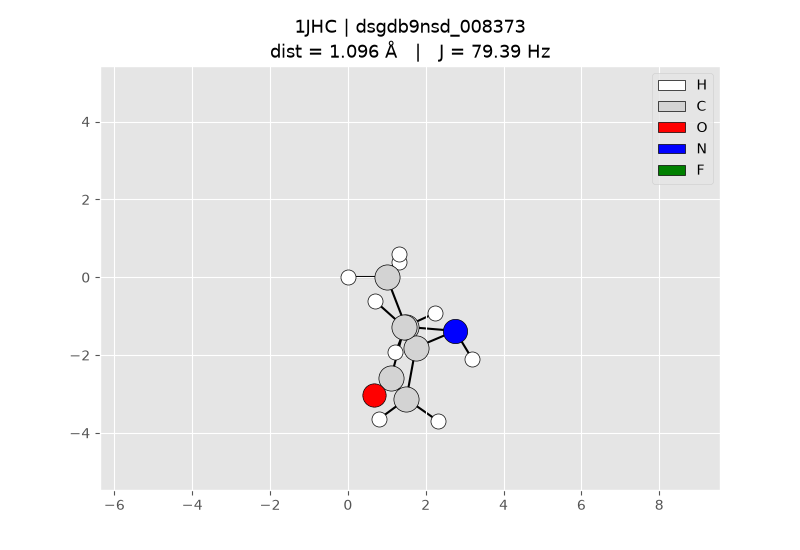

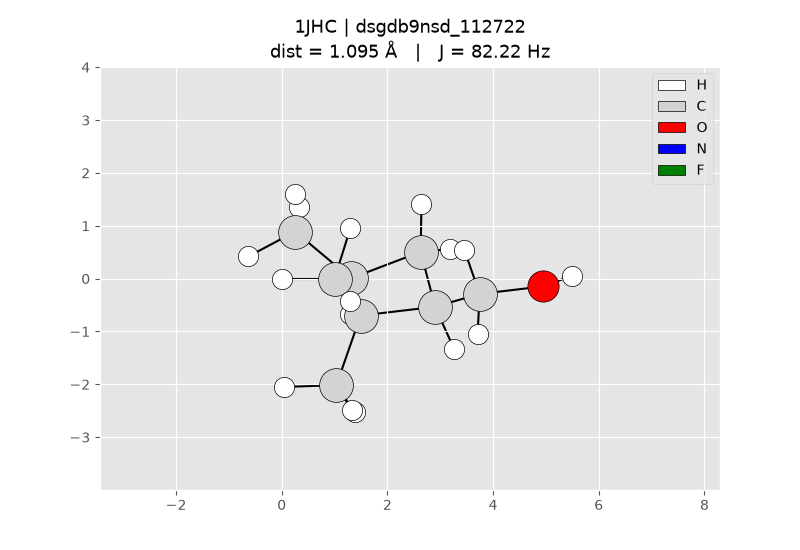

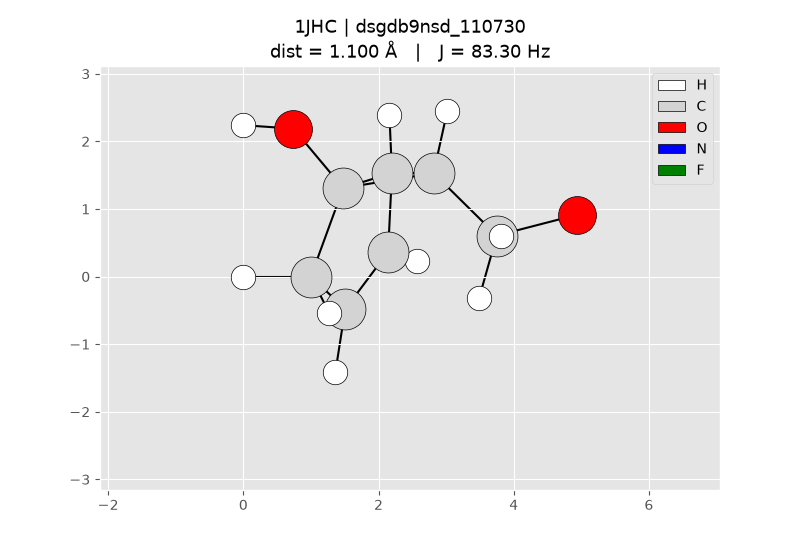

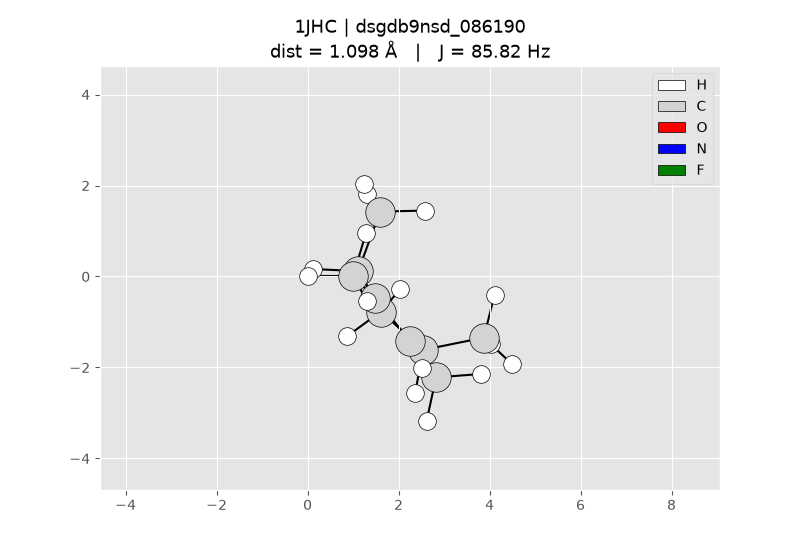

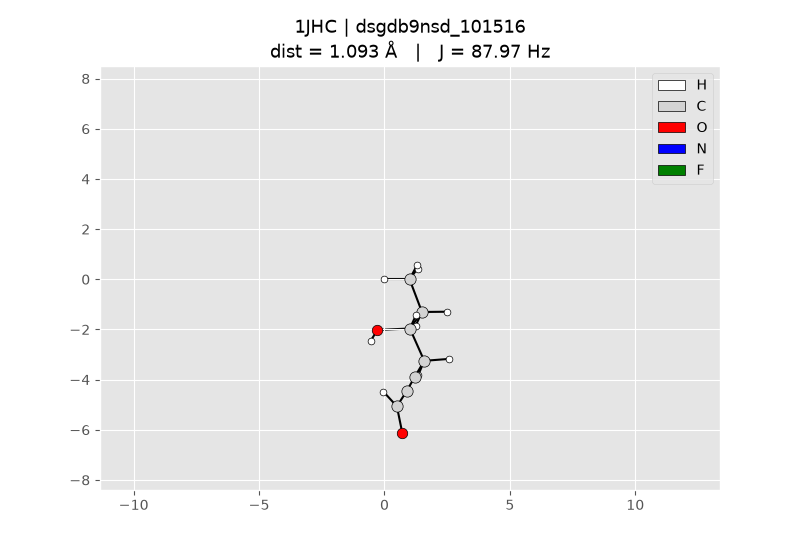

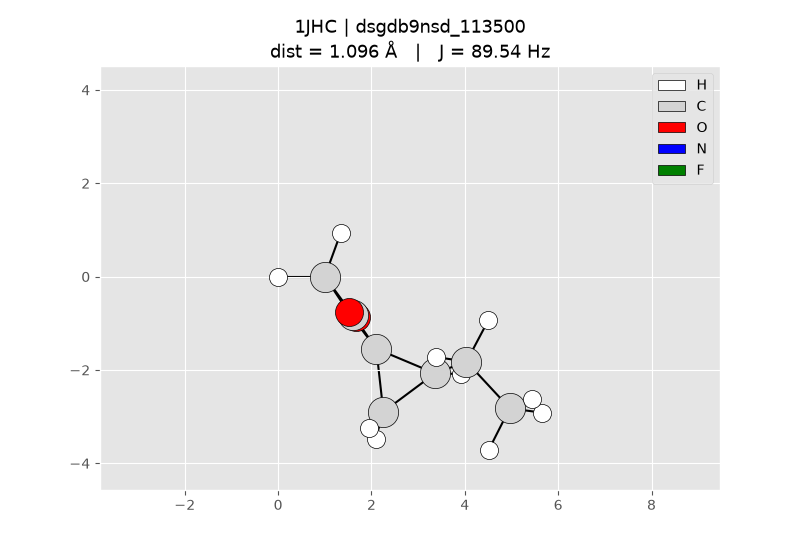

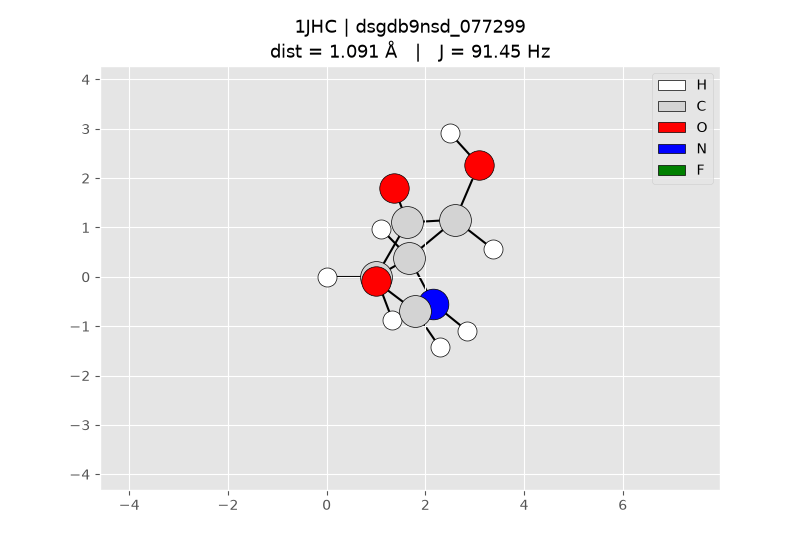

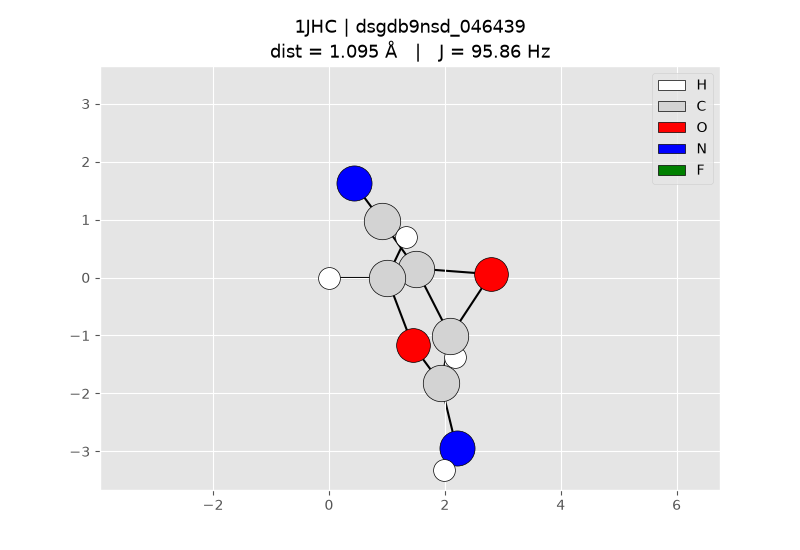

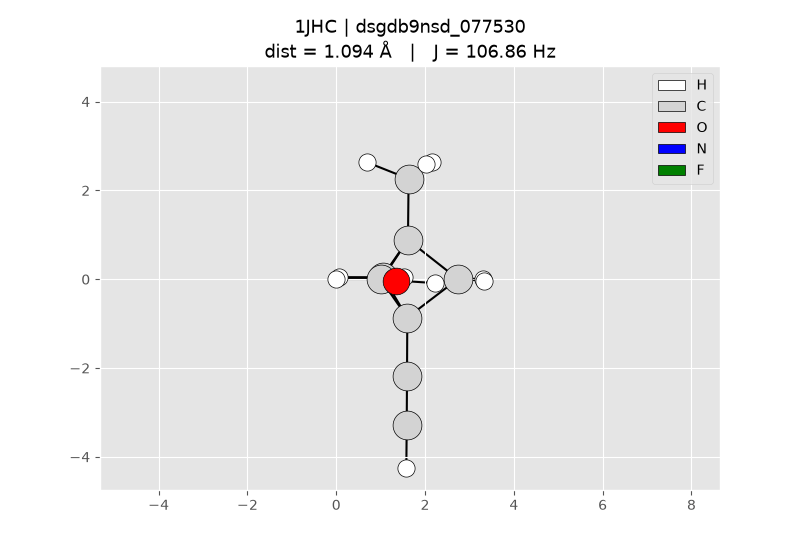

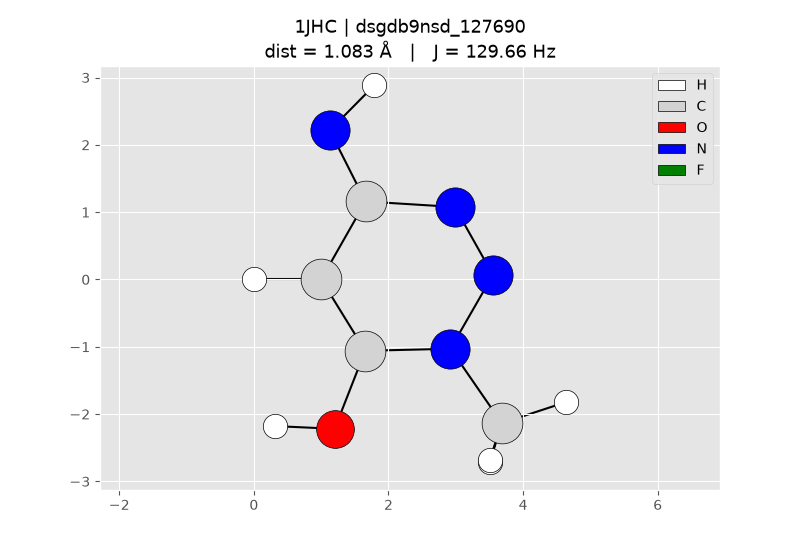

In [33]:
cols = ['molecule_name', 'atom_index_0', 'atom_index_1', 'dist', 'scalar_coupling_constant']
for name, idx in groups.items():
    print(f'\n######## {TYPE} | {name} ########')
    if not idx:
        print('(had zone farghin)')
        continue
    print(train_df.loc[idx, cols].round(3).to_string())
    for j in idx:
        animate(j)

In [ ]:
TYPE  = '1JHC'
BOND_CUTOFF = 1.65
FEATS =  ['n_bonds', 'n_H', 'n_C', 'n_O', 'n_N',
         'min_heavy_bl', 'mean_bl', 'mean_angle']
F = {name: np.full(len(structures), np.nan, dtype='float32') for name in FEATS}

for k in range(len(ssx) - 1 ):
    a , b = ssx[k], ssx[k+1]
    n = b -a 
    xyz = np_xyz[a : b].astype('float')
    at= np_atoms[a : b]
    diff = xyz[None, : , :] - xyz[:, None,  : ]
    d = np.linalg.norm(diff , axis = 2)
    B    = (d < BOND_CUTOFF) & (d > 0)     
    nb = B.sum(1)
    F['n_bonds'][a : b] = nb 
    for code, name in enumerate(['n_H', 'n_C', 'n_O', 'n_N', 'n_F']):
        F[name][a:b] = (B & (at == code)[None, :]).sum(1)
    
    dh = np.where(B & (at != 0)[None, :], d, np.inf)
    mn = dh.min(1); mn[np.isinf(mn)] = np.nan
    F['min_heavy_bl'][a:b] = mn
    F['mean_bl'][a:b]      = np.where(nb > 0, (d * B).sum(1) / np.maximum(nb, 1), np.nan)
    u   = diff / np.where(d > 0, d, 1.0)[:, :, None]
    cos = np.clip(np.einsum('ijc,ikc->ijk', u, u), -1, 1)
    M   = B[:, :, None] & B[:, None, :] & np.triu(np.ones((n, n), bool), 1)[None, :, :]
    ang = np.degrees(np.arccos(np.where(M, cos, 0.0)))
    cnt = M.sum((1, 2))
    F['mean_angle'][a:b] = np.where(cnt > 0, (ang * M).sum((1, 2)) / np.maximum(cnt, 1), np.nan)

def add_atom_feats(df, col='atom_index_1', prefix='a1_'):
 
    rows = ssx[df['molecule_name'].map(np_dict).values.astype(int)] + df[col].values
    for name, arr in F.items():
        df[prefix + name] = arr[rows]
    return df
train_df = add_atom_feats(train_df)
test_df  = add_atom_feats(test_df)
print('ney coluéns :', [c for c in train_df.columns if c.startswith('a1_')])

sub = train_df[train_df['type'] == TYPE].copy()
bg  = sub.sample(min(30000, len(sub)), random_state=50)
J   = 'scalar_coupling_constant'

fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))
for v, g in bg.groupby('a1_n_bonds'):
    axes[0].scatter(g['dist'], g[J], s=3, alpha=0.4, label=f'n_bonds = {int(v)}')
axes[0].legend(markerscale=5)
axes[0].set_title(f'{TYPE} n_bonds colored (4=sp3 , 3=sp2 , 2=sp)')

for ax, col, ttl in [(axes[1], 'a1_mean_angle',  'mean_angle  (109=sp3 , 120=sp2 , 180=sp)'),
                     (axes[2], 'a1_min_heavy_bl', 'min_heavy_bl  (shortest liaison lourde)')]:
    sc = ax.scatter(bg['dist'], bg[J], c=bg[col], s=3, alpha=0.5, cmap='viridis')
    plt.colorbar(sc, ax=ax)
    ax.set_title(f'{TYPE} mloun b {ttl}')
for ax in axes:
    ax.set_xlabel('dist (Å)'); ax.set_ylabel('J (Hz)')
plt.tight_layout()
plt.show()
res = (sub.groupby('a1_n_bonds')
          .apply(lambda g: pd.Series({
              'n'          : len(g),
              'J_mean'     : g[J].mean(),
              'dist_mean'  : g['dist'].mean(),
              'corr_dist_J': g['dist'].corr(g[J])}))
          .round(3))
print(res)


ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

# Conclusion: EDA and feature-engineering plan (CHAMPS scalar coupling)

## 1. Goal
Predict `scalar_coupling_constant` (J, Hz) between two atoms of a molecule from its 3D
structure. There are 8 coupling types (1JHC, 1JHN, 2JHH, 2JHC, 2JHN, 3JHH, 3JHC, 3JHN).
So far the notebook covers EDA only; no model has been trained yet.

## 2. What we did
- Loaded structures / train / test and compared the type distributions.
- Plotted the J distribution for each type.
- Built `dist` (Euclidean distance between the two atoms) and measured its correlation with J per type.
- Built `standardizer` (H at the origin, second atom at (1,0,0)) and animated molecules.

## 3. Findings
| Type | corr(dist, J) | Reading |
|---|---|---|
| 1JHN | -0.87 | strong, clean, monotonic (Spearman -0.90) |
| 1JHC | -0.71 | misleading (Spearman only -0.50): 3-4 distinct zones |
| 2JHH | 0.53 | moderate |
| 2JHC, 3JHC, 3JHH, 3JHN | 0.26 to 0.32 | weak |
| 2JHN | -0.16 | almost none |

- 1J couplings (one bond): the distance is the bond length, so `dist` is a strong feature.
  For 1JHN it is almost enough on its own.
- 2J and 3J couplings (two or three bonds): `dist` alone is weak. J depends others features


## 4. 1JHC: hypothesis (to be verified)
The same C-H distance can give very different J values. Hypothesis: the hybridisation
of the carbon (number of neighbours: sp = 2, sp2 = 3, sp3 = 4) controls both
the bond length and J through its s-character (sp > sp2 > sp3).
- ~1.06 A, J ~195: sp zone (small cluster)
- 1.075-1.09 A, J 105-140: sp2 zone
- 1.09-1.10 A, J 80-107: sp3 zone (dense region)
- > 1.105 A, J 105-135: right-hand branch, cause still unknown




**found a features for reforcing my predictor model for that type of BONd 1j**


In [ ]:

test_df



,id,molecule_name,atom_index_0,atom_index_1,type
0,4659076,dsgdb9nsd_000004,2,0,2JHC
1,4659077,dsgdb9nsd_000004,2,1,1JHC
2,4659078,dsgdb9nsd_000004,2,3,3JHH
3,4659079,dsgdb9nsd_000004,3,0,1JHC
4,4659080,dsgdb9nsd_000004,3,1,2JHC
...,...,...,...,...,...
2505185,7164261,dsgdb9nsd_133885,15,3,2JHC
2505186,7164262,dsgdb9nsd_133885,15,4,2JHC
2505187,7164263,dsgdb9nsd_133885,15,6,3JHC
2505188,7164264,dsgdb9nsd_133885,15,7,2JHC


In [ ]:
def build_summary(df : pd.DataFrame) -> pd.DataFrame:
    rows = []
    for column in df.columns:
        rows.append({
            'Column Name': column
             , 'Data Type': df[column].dtype
            , 'Missing Values': df[column].isnull().sum() , 
            'missing pct ' : df[column].isnull().sum() / len(df) * 100 , 
            'nunique': int(df[column].nunique()),
                      'sample_values': ','.join(df[column].dropna().astype(str).unique()[:4]),
                  })




    return pd.DataFrame(rows)


In [ ]:
TARGET = ['scalar_coupling_constant']

eda_cols = [c for c in train_df.columns if c not in TARGET ]
eda_summary = build_summary(train_df[eda_cols])
print(eda_summary)
     


     Column Name Data Type  Missing Values  missing pct   nunique  \
0             id     int64               0           0.0  4659076   
1  molecule_name    object               0           0.0    85012   
2   atom_index_0     int64               0           0.0       28   
3   atom_index_1     int64               0           0.0       29   
4           type    object               0           0.0        8   

                                       sample_values  
0                                            0,1,2,3  
1  dsgdb9nsd_000001,dsgdb9nsd_000002,dsgdb9nsd_00...  
2                                            1,2,3,4  
3                                            0,2,3,4  
4                                1JHC,2JHH,1JHN,2JHN  


In [ ]:
eda_cols_test = [c for c in test_df.columns]
eda_summary_test = build_summary(test_df[eda_cols_test])
print(eda_summary_test)



     Column Name Data Type  Missing Values  missing pct   nunique  \
0             id     int64               0           0.0  2505190   
1  molecule_name    object               0           0.0    45777   
2   atom_index_0     int64               0           0.0       29   
3   atom_index_1     int64               0           0.0       29   
4           type    object               0           0.0        8   

                                       sample_values  
0                    4659076,4659077,4659078,4659079  
1  dsgdb9nsd_000004,dsgdb9nsd_000014,dsgdb9nsd_00...  
2                                            2,3,4,5  
3                                            0,1,3,4  
4                                2JHC,1JHC,3JHH,2JHH  


In [ ]:
df_scalar_coupling_contributions = pd.read_csv(os.path.join(DATA_DIR, 'scalar_coupling_contributions.csv'))

df_scalar_coupling_contributions.head(3)

,molecule_name,atom_index_0,atom_index_1,type,fc,sd,pso,dso
0,dsgdb9nsd_000001,1,0,1JHC,83.0224,0.254579,1.25862,0.27201
1,dsgdb9nsd_000001,1,2,2JHH,-11.0347,0.352978,2.85839,-3.43360
2,dsgdb9nsd_000001,1,3,2JHH,-11.0325,0.352944,2.85852,-3.43387


In [ ]:
test_features = pd.concat([df_scalar_coupling_contributions, test_df], ignore_index=True)
test_features 

,molecule_name,atom_index_0,atom_index_1,type,fc,sd,pso,dso,id
0,dsgdb9nsd_000001,1,0,1JHC,83.0224,0.254579,1.25862,0.272010,NaN
1,dsgdb9nsd_000001,1,2,2JHH,-11.0347,0.352978,2.85839,-3.433600,NaN
2,dsgdb9nsd_000001,1,3,2JHH,-11.0325,0.352944,2.85852,-3.433870,NaN
3,dsgdb9nsd_000001,1,4,2JHH,-11.0319,0.352934,2.85855,-3.433930,NaN
4,dsgdb9nsd_000001,2,0,1JHC,83.0222,0.254585,1.25861,0.272013,NaN
...,...,...,...,...,...,...,...,...,...
7164261,dsgdb9nsd_133885,15,3,2JHC,NaN,NaN,NaN,NaN,7164261.0
7164262,dsgdb9nsd_133885,15,4,2JHC,NaN,NaN,NaN,NaN,7164262.0
7164263,dsgdb9nsd_133885,15,6,3JHC,NaN,NaN,NaN,NaN,7164263.0
7164264,dsgdb9nsd_133885,15,7,2JHC,NaN,NaN,NaN,NaN,7164264.0


In [ ]:
test_features.to_csv(r"C:\Users\pc\Downloads\champs-scalar-coupling\test_features.csv", index=False)

In [ ]:
test_features.drop(columns= ['id'] )



,molecule_name,atom_index_0,atom_index_1,type,fc,sd,pso,dso
0,dsgdb9nsd_000001,1,0,1JHC,83.0224,0.254579,1.25862,0.272010
1,dsgdb9nsd_000001,1,2,2JHH,-11.0347,0.352978,2.85839,-3.433600
2,dsgdb9nsd_000001,1,3,2JHH,-11.0325,0.352944,2.85852,-3.433870
3,dsgdb9nsd_000001,1,4,2JHH,-11.0319,0.352934,2.85855,-3.433930
4,dsgdb9nsd_000001,2,0,1JHC,83.0222,0.254585,1.25861,0.272013
...,...,...,...,...,...,...,...,...
7164261,dsgdb9nsd_133885,15,3,2JHC,NaN,NaN,NaN,NaN
7164262,dsgdb9nsd_133885,15,4,2JHC,NaN,NaN,NaN,NaN
7164263,dsgdb9nsd_133885,15,6,3JHC,NaN,NaN,NaN,NaN
7164264,dsgdb9nsd_133885,15,7,2JHC,NaN,NaN,NaN,NaN


In [ ]:
eda_cols_test_feature = [c for c in test_features.columns]
eda_summary_test = build_summary(test_features[eda_cols_test_feature])
print(eda_summary_test)




     Column Name Data Type  Missing Values  missing pct   nunique  \
0  molecule_name    object               0      0.000000   130789   
1   atom_index_0     int64               0      0.000000       29   
2   atom_index_1     int64               0      0.000000       29   
3           type    object               0      0.000000        8   
4             fc   float64         2505190     34.967853  2170719   
5             sd   float64         2505190     34.967853   577108   
6            pso   float64         2505190     34.967853  1356440   
7            dso   float64         2505190     34.967853  1443358   
8             id   float64         4659076     65.032147  2505190   

                                       sample_values  
0  dsgdb9nsd_000001,dsgdb9nsd_000002,dsgdb9nsd_00...  
1                                            1,2,3,4  
2                                            0,2,3,4  
3                                1JHC,2JHH,1JHN,2JHN  
4                 83.0224,-11.0347

In [ ]:
yellow, cyan_g, cyan_dark = "#F7C53E", "#0CF7AF", "#11AB7C"
purple, purple_dark, purple_light = "#D826F8", "#9309AB", "#b683d6"
blue, red, orange, green = "#0C97FA", "#FA1D19", "#FA9F19", "#0CFA58"
light_blue, soft_blue, dark_blue = "#01FADC", "#81c9e6", "#394be6"


PALETTE_2 = [cyan_g, purple]
PALETTE_3 = [yellow, cyan_g, purple]
PALETTE_7 = [purple_dark, purple_light, purple, blue, light_blue, dark_blue, soft_blue]